# №1 зертханалық жұмыс
## Машиналық оқыту моделін құрудың негізгі кезеңдері: міндетті қою, белгілерді дайындау, деректерді бөлу және базалық модельді құру.

Мақсат — міндетті тұжырымдау, белгілерді тексеру, оқытудан бұрын тестті бөлу, аңғал және оқытылатын модельдерді салыстыру, қателерді түсіндіру.

Кірістірілген Iris және синтетикалық деп анық белгіленген жүктеме орта орнатылғаннан кейін желісіз жұмыс істейді. Барлық әрекет жергілікті орындалады. Бағдарлама деректерді жібермейді. Байланысты материалдар — 1-тараудың 1.10–1.11-бөлімдері және `lab01.py` скрипті.

Орындау реті — Python ядросын іске қосып, барлық ұяшықты жоғарыдан төмен орындаңыз. Кестелерді зерттеп, содан кейін жауап өрістеріне өз түсіндірмелеріңізді енгізіңіз. Сақталған шығыстар тексерілген іске қосуды көрсетеді. Олар өз бетіңізше талдау жасауды алмастырмайды.

### 1–3-қадамдар. Міндетті қою және деректер
Iris үшін бір объект — гүл, жауап — түрі, белгілер — сантиметрмен өлшенген төрт шама. Деректер scikit-learn құрамында жүктеледі. Түр атаулары мен сандық кодтарды ажырату қажет. Жүктеме үшін шартты бірліктердегі синтетикалық деректер ғана пайдаланылады.

Бағдарламалық құралдар — Python, NumPy, pandas, scikit-learn, Matplotlib, Jupyter. Келесі ұяшық нақты нұсқаларды хабарлайды. Алдымен өлшемді, жетіспейтін мәндерді және класс жиіліктерін тексеріңіз.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             mean_absolute_error, mean_squared_error, r2_score)

plt.rcParams["font.family"] = "DejaVu Sans"
FIGURES = Path.cwd() / "lab01_figures"
FIGURES.mkdir(parents=True, exist_ok=True)


from IPython.display import display, Image
from importlib.metadata import version
for package in ("numpy", "pandas", "scikit-learn", "matplotlib"):
    print(package, version(package))


numpy 2.5.4
pandas 3.0.1
scikit-learn 1.9.1
matplotlib 3.11.2


In [2]:
iris_data = load_iris(as_frame=True)
display(iris_data.frame.head())
print("Өлшем", iris_data.frame.shape)
print("Жетіспейтін мәндер", iris_data.frame.isna().sum().to_dict())
print("Жиіліктер", iris_data.target.value_counts().sort_index().to_dict())
print(iris_data.DESCR)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Өлшем (150, 5)
Жетіспейтін мәндер {'sepal length (cm)': 0, 'sepal width (cm)': 0, 'petal length (cm)': 0, 'petal width (cm)': 0, 'target': 0}
Жиіліктер {0: 50, 1: 50, 2: 50}
.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.2

**Сіздің жауабыңыз.** Бақылау бірлігін, әр белгінің мағынасын және мақсатты айнымалыны сипаттаңыз. 0, 1, 2 кодтары кластарды неліктен білдіретінін түсіндіріңіз.

_Өз түсіндірмеңізді осы жерге жазыңыз._

### 4–7-қадамдар. Бөлу, базалық модель және қателер матрицасы
Төмендегі функция Iris-ті стратификациямен және `random_state=42` арқылы 80/20 қатынасымен бөледі. `DummyClassifier(most_frequent)` және `Pipeline(StandardScaler, LogisticRegression(max_iter=1000))` салыстырылады. Оқыту мен бағалау әртүрлі бөліктерде орындалады. Масштабтау параметрлерді оқытылатын конвейер ішінде алады.

             model  accuracy  F1macro
             Dummy  0.333333 0.166667
LogisticRegression  0.933333 0.933333
{'Dummy': [[10, 0, 0], [10, 0, 0], [10, 0, 0]], 'LogisticRegression': [[10, 0, 0], [0, 9, 1], [0, 1, 9]]}


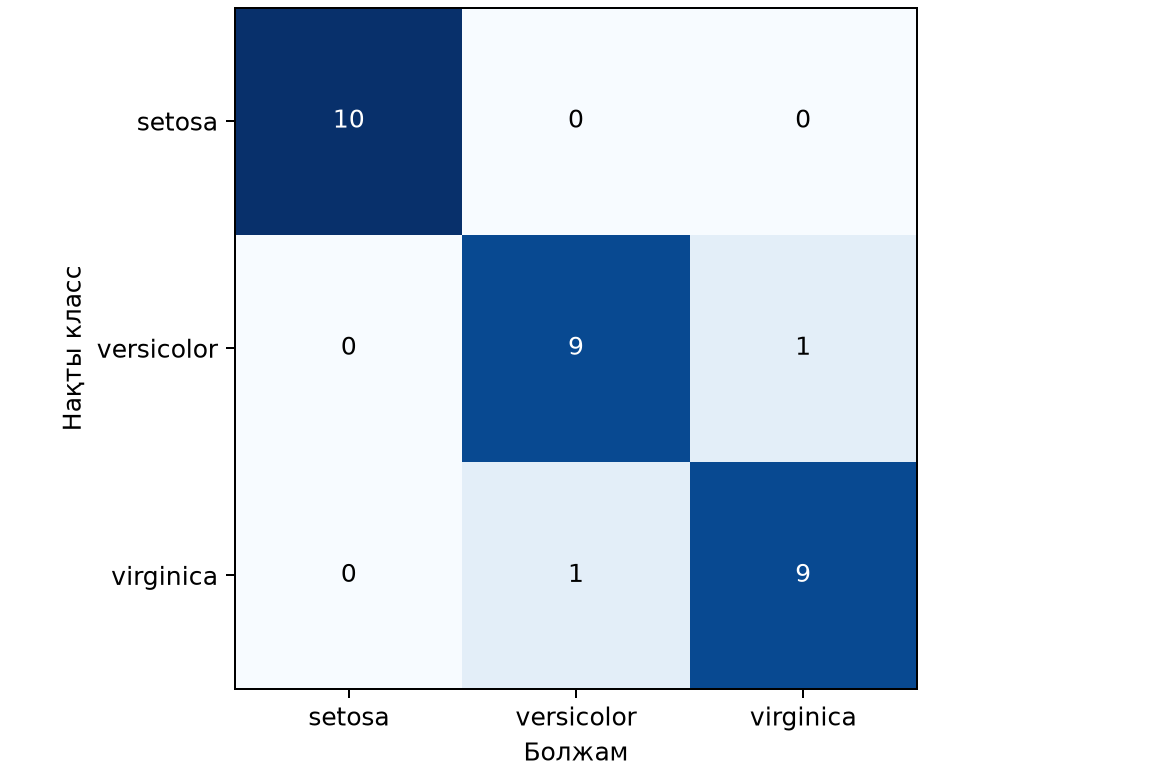

In [3]:
def iris_experiment():
    data = load_iris(as_frame=True)
    X, y = data.data, data.target
    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=42)
    models = {
        "Dummy": DummyClassifier(strategy="most_frequent"),
        "LogisticRegression": Pipeline([
            ("scale", StandardScaler()),
            ("model", LogisticRegression(max_iter=1000))])}
    rows, matrices = [], {}
    for name, model in models.items():
        model.fit(Xtr, ytr)
        pred = model.predict(Xte)
        rows.append({"model": name, "accuracy": accuracy_score(yte, pred),
                     "F1macro": f1_score(yte, pred, average="macro")})
        matrices[name] = confusion_matrix(yte, pred, labels=[0, 1, 2]).tolist()
    fig, ax = plt.subplots(figsize=(6.4, 4.3), layout="constrained")
    matrix = np.array(matrices["LogisticRegression"])
    ax.imshow(matrix, cmap="Blues", vmin=0)
    ax.set(xticks=range(3), yticks=range(3), xticklabels=data.target_names,
           yticklabels=data.target_names, xlabel="Болжам", ylabel="Нақты класс")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, str(matrix[i, j]), ha="center", va="center",
                    color="white" if matrix[i, j] > 5 else "black")
    fig.savefig(FIGURES / "ch01_05_iris.png", dpi=180)
    plt.close(fig)
    print(pd.DataFrame(rows).to_string(index=False))
    return {"train_size": len(ytr), "test_size": len(yte),
            "metrics": rows, "confusion_matrices": matrices}


iris_result = iris_experiment()
print(iris_result["confusion_matrices"])
display(Image(filename=str(FIGURES / "ch01_05_iris.png")))


Матрица жолдары нақты түрлерге, бағандары болжамдарға сәйкес келеді. Тексерілген іске қосуда 30 объектінің 28-і дұрыс танылған. Accuracy және F1-macro шамамен 0,9333-ке тең. Аңғал ереженің Accuracy көрсеткіші 0,3333, F1-macro көрсеткіші 0,1667 болады. Екі қате жауап versicolor мен virginica арасында орналасқан.

**Сіздің жауабыңыз.** Матрицаның бір ұяшығын түсіндіріп, қателер себебі туралы тексерілетін гипотеза ұсыныңыз. Нәтижені көргеннен кейін сәттірек seed таңдауы хаттаманы неліктен бұзады?

_Өз түсіндірмеңізді осы жерге жазыңыз._

### 8-қадам. Синтетикалық жүктеме регрессиясы
2026 генераторымен жасалған тәуелсіз бақылауларды пайдаланамыз. Температура −5-тен 30-ға, қатысу үлесі 0-ден 1-ге дейін; `y = 120 - 2.5*T + 45*q + noise`, шудың стандарттық ауытқуы 6. Бұл — оқу генерациясы, нақты өлшемдер емес. Бөлу — 80/20. Train бойынша орташа мән мен сызықтық регрессия салыстырылады.

           model       MAE      RMSE        R2
           Dummy 22.409559 26.528474 -0.009478
LinearRegression  4.785083  5.647633  0.954248
Коэффициенттер [-2.4383417452943643, 44.33226187767561]
Бос мүше 119.02818906284129


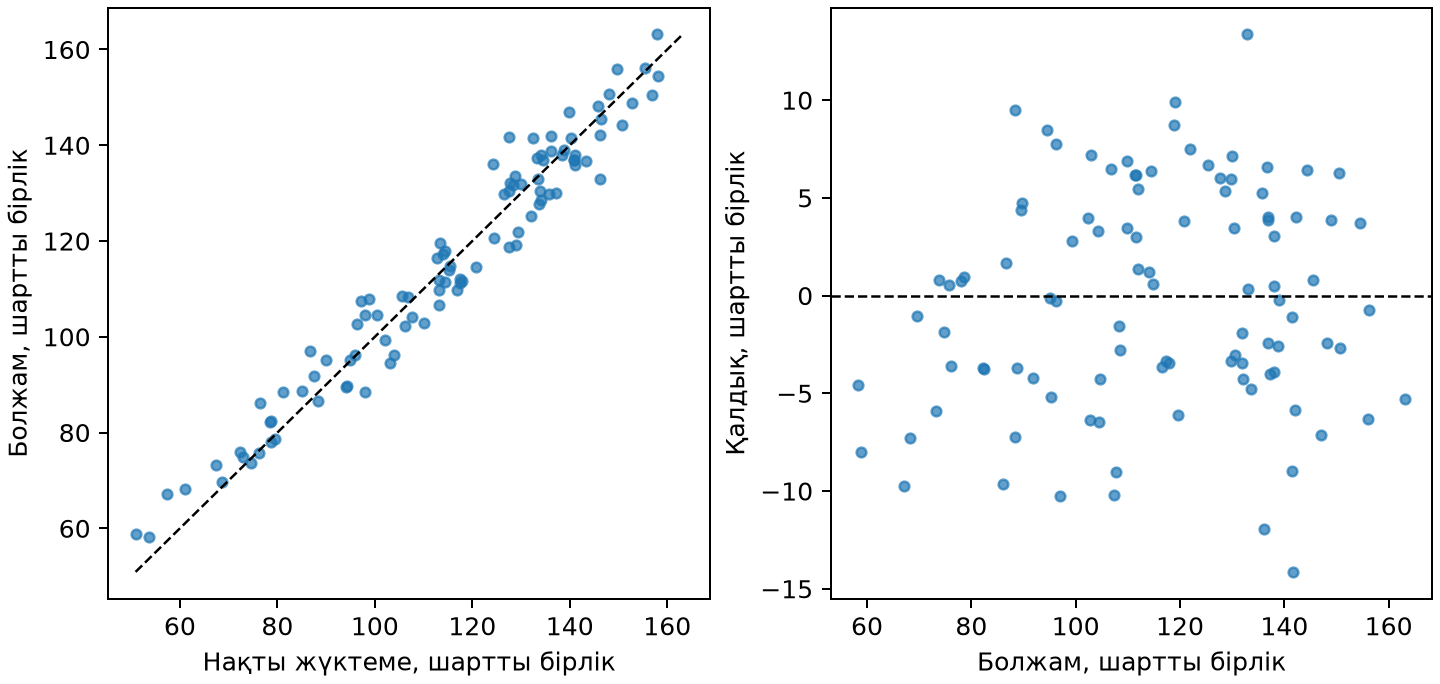

In [4]:
def regression_experiment():
    rng = np.random.default_rng(2026)
    n = 500
    temperature = rng.uniform(-5, 30, n)
    occupancy = rng.uniform(0, 1, n)
    X = pd.DataFrame({"temperature_C": temperature, "occupancy": occupancy})
    y = 120 - 2.5 * temperature + 45 * occupancy + rng.normal(0, 6, n)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=2026)
    models = {"Dummy": DummyRegressor(strategy="mean"),
              "LinearRegression": LinearRegression()}
    rows, predictions = [], {}
    for name, model in models.items():
        model.fit(Xtr, ytr)
        pred = model.predict(Xte)
        rows.append({"model": name, "MAE": mean_absolute_error(yte, pred),
                     "RMSE": np.sqrt(mean_squared_error(yte, pred)),
                     "R2": r2_score(yte, pred)})
        predictions[name] = pred
    fig, axs = plt.subplots(1, 2, figsize=(8, 3.8), layout="constrained")
    pred = predictions["LinearRegression"]
    limits = [min(yte.min(), pred.min()), max(yte.max(), pred.max())]
    axs[0].scatter(yte, pred, s=15, alpha=0.7)
    axs[0].plot(limits, limits, "k--", linewidth=1)
    axs[0].set(xlabel="Нақты жүктеме, шартты бірлік", ylabel="Болжам, шартты бірлік")
    axs[1].scatter(pred, yte - pred, s=15, alpha=0.7)
    axs[1].axhline(0, color="black", linestyle="--", linewidth=1)
    axs[1].set(xlabel="Болжам, шартты бірлік", ylabel="Қалдық, шартты бірлік")
    fig.savefig(FIGURES / "ch01_06_regression.png", dpi=180)
    plt.close(fig)
    print(pd.DataFrame(rows).to_string(index=False))
    return {"synthetic": True, "seed": 2026, "train_size": len(ytr),
            "test_size": len(yte), "metrics": rows,
            "coefficients": models["LinearRegression"].coef_.tolist(),
            "intercept": float(models["LinearRegression"].intercept_)}


regression_result = regression_experiment()
print("Коэффициенттер", regression_result["coefficients"])
print("Бос мүше", regression_result["intercept"])
display(Image(filename=str(FIGURES / "ch01_06_regression.png")))


Тексерілген іске қосуда сызықтық модельдің MAE көрсеткіші 4,7851, RMSE көрсеткіші 5,6476, R² көрсеткіші 0,95425 болады. Оқыту бөлігінің орташа мәні MAE 22,4096 береді. Бұл мәндер осы синтетикалық іріктемеге ғана қатысты.

**Сіздің жауабыңыз.** MAE бірліктерін, диагональ мен қалдықтардың мағынасын түсіндіріңіз. Табылған коэффициенттер генератор параметрлерінен неліктен өзгеше? Кездейсоқ бөлу мұнда неліктен жарамды, ал нақты уақыт қатары үшін жарамсыз болуы мүмкін?

_Өз түсіндірмеңізді осы жерге жазыңыз._

### Сандық өзін-өзі тексеру
Келесі ұяшық нақ базалық эксперименттің құрылымын тексереді. Ол түсіндірмелеріңіздің сапасын бағаламайды және әр нұсқадағы метрикалардың соңғы цифрына дейін сәйкес келуін талап етпейді. `check_accuracy` функциясы дұрыс жауаптар үлесін қолмен есептеуді тексеруге мүмкіндік береді.

In [5]:
assert iris_result["train_size"] == 120 and iris_result["test_size"] == 30
for matrix in iris_result["confusion_matrices"].values():
    assert np.asarray(matrix).shape == (3, 3)
    assert np.asarray(matrix).sum() == 30
assert regression_result["train_size"] == 400
assert regression_result["test_size"] == 100
assert regression_result["synthetic"] is True
print("Бөліктердің өлшемдері мен қателер матрицалары хаттамаға сәйкес.")

def check_accuracy(correct, total, answer):
    if not 0 <= correct <= total or total <= 0:
        raise ValueError("Дұрыс жауаптар саны мен тест көлемін тексеріңіз")
    ok = np.isclose(answer, correct / total)
    return "Дұрыс" if ok else "Дұрыс жауаптар саны / тест көлемі қатынасын қайта есептеңіз"

print("Мысал: 30 жауаптың 27-сі:", check_accuracy(27, 30, 0.9))


Бөліктердің өлшемдері мен қателер матрицалары хаттамаға сәйкес.
Мысал: 30 жауаптың 27-сі: Дұрыс


### 9-қадам. Жеке нұсқа
Бастапқы экспериментті сақтаңыз. Таңдалған нұсқа үшін жеке ұяшықтар қосыңыз:

1. Iris: тостағанша және күлте жапырақша белгілерін салыстырыңыз.
2. Wine: сол конвейерді `load_wine(as_frame=True)` жиынтығына қолданыңыз.
3. Digits: конвейерді `load_digits(as_frame=True)` жиынтығына қолданып, екі цифрдың шатастырылуын түсіндіріңіз.
4. Синтетикалық жүктеме: шудың стандарттық ауытқуын 12-ге дейін арттырыңыз.
5. Синтетикалық жүктеме: бастапқы жауапты сақтап, қатысу белгісін `X` құрамынан алып тастаңыз.
6. Синтетикалық жүктеме: жауапқа `0.12 * temperature**2` қосыңыз.

Бір тәжірибеде бір себепті өзгертіңіз. Алдын ала жоспарланған барлық нәтижені хабарлаңыз, ең жақсы seed таңдамаңыз. Модельді жүйелі баптауға жеке валидация қажет болады.

**Сіздің нұсқаңыз, гипотезаңыз және хаттамаңыз.**

_Нөмірді, гипотезаны, өзгерісті және метрикаларды осы жерге жазыңыз. Төменге өз код ұяшықтарыңызды қосыңыз._

### 10-қадам. Есеп және таза іске қосу
Ядроны қайта іске қосып, бәрін жаңадан орындаңыз және Notebook-ті сақтаңыз. Есеп құрамына міндеттің қойылуы, деректер мен белгілер сөздігі, бөлу хаттамасы, код, кесте, атаулары көрсетілген екі график, қателерді талдау, қорытынды және кітапхана нұсқалары кіреді.

100%-дық жергілікті рубрика: міндетті қою 15%; деректерді тексеру 15%; бөлу және деректердің ағып кетуінен қорғау 20%; екі есептік бастау нүктесі 20%; түсіндіру және қателер 20%; қайталанымдылық 10%. Рубрика силлабустың ресми балдарын алмастырмайды. Қайта есептеуді оқытушы орындайды.

Бақылау сұрақтары: бақылау деген не; target неліктен белгілерге кірмеуі керек; scaler үшін fit қашан шақырылады; DummyClassifier не үшін қажет; модельдер неліктен бір тестте салыстырылады; F1-macro мен Accuracy айырмасы қандай; матрицаны қалай оқу керек; теріс R² жарамды ма; уақыт қатары үшін не өзгереді; қайталанымдылықты қандай мәліметтер қамтамасыз етеді?

Дереккөздер: Оспан Ә.Ғ. авторлық 1-дәрісі мен 1-зертханалық жұмысы; [Iris](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html), [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html), [Common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html). Жүктеме деректері мен графиктер осы оқу мысалы үшін жасалған.